# Llama 3.2-3B Energy Ablation — Final (v4)

**CSE407 Green Computing · T4 GPU · 10 Hz pynvml power monitoring**

| Config | Weights | Eviction | KV Cache |
|--------|---------|----------|----------|
| C0 | FP16 | None | FP16 |
| C1 | AWQ 4-bit | None | FP16 |
| C2 | AWQ 4-bit | PyramidKV | FP16 |
| C3 | AWQ 4-bit | None | TurboQuant 4-bit |
| C4 | AWQ 4-bit | PyramidKV | TurboQuant 4-bit |

> **Contexts**: 1024, 2048, 4096
> **NIAH depths**: 0.1, 0.3, 0.5, 0.7, 0.9 (5 depths per cell)
> **Decode length**: 128 tokens (fair test for PyramidKV)

### What this version fixes (v3 → v4)

**Fix 1: Longer decode (max_new = 128, was 32)**
PyramidKV evicts the cache AFTER prefill attention. With only 32 decode tokens,
decode is ~5% of total energy — too small for PyramidKV's savings to show.
At 128 tokens, decode is ~15-20% of total energy, giving PyramidKV a fair test.

**Fix 2: Multi-depth NIAH (5 depths, was 1)**
The single-depth (0.5) test gave 100% everywhere — no quality differentiation.
Testing at depths [0.1, 0.3, 0.5, 0.7, 0.9] probes the "lost in the middle"
phenomenon. Some depths are harder; compression may break retrieval there.

**Fix 3: Harder needle format**
Previous needle "The secret project code name is SHADOW-8821" with cloze
"The secret project code name is ___" was trivial pattern completion.
New needle uses a random activation code with no semantic priming.

### Carried over from v3
- transformers 5.x Cache API (`cache.layers[i].keys/.values`)
- PyramidKV attend-then-evict (confirmed correct by official repo)
- Decode position_ids + no attention_mask
- Warmup discard, eviction logging, PPL + response logging
- Sanity check (C2 with budget=ctx_len)
- Statistics with Cohen's d and Bonferroni correction

### Research framing

This study tests whether combining AWQ, PyramidKV, and TurboQuant on an SLM
(Llama-3.2-3B) on an edge GPU (T4) is beneficial. **The expected finding is
negative**: the combination is counterproductive because overheads exceed
savings on this hardware class. This is a genuine, novel contribution.


## 1. Install
Run once, then **Runtime → Restart session**.

In [1]:
!pip install -q autoawq==0.2.9 gptqmodel turboquant
!pip install -q transformers accelerate nvidia-ml-py pandas matplotlib scipy
print('Done — restart the Colab session (Runtime -> Restart session) before continuing.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 21.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.8/121.8 kB 5.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.8/97.8 kB 11.5 MB/s eta 0:00:00
  Installing build

## 2. Imports & Configuration

In [1]:
import gc, os, threading, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Force memory-efficient SDPA on T4 (which lacks FlashAttention-2)
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import pynvml
from transformers import AutoModelForCausalLM, AutoTokenizer, DynamicCache, set_seed
from transformers.models.llama.modeling_llama import (
    LlamaAttention, apply_rotary_pos_emb, repeat_kv, eager_attention_forward
)
from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS
from turboquant import TurboQuantCache

# ── Hardware ──
pynvml.nvmlInit()
HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)

# ── Config ──
SEED = 407
MODEL_BF16 = 'unsloth/Llama-3.2-3B-Instruct'
MODEL_AWQ  = 'casperhansen/llama-3.2-3b-instruct-awq'
CONTEXTS    = [1024, 2048, 4096]
DEPTHS      = [0.1, 0.3, 0.5, 0.7, 0.9]   # multi-depth NIAH
REPETITIONS = 5
WARMUP_DISCARD = 1
MAX_NEW      = 128    # longer decode — fair test for PyramidKV

set_seed(SEED)
torch.manual_seed(SEED); np.random.seed(SEED)

assert torch.cuda.is_available(), 'CUDA GPU required.'
PROPS = torch.cuda.get_device_properties(0)
print(f'GPU: {PROPS.name} | VRAM: {PROPS.total_memory/2**30:.1f} GB | SM: {PROPS.major}.{PROPS.minor}')

# ── Verify transformers version & Cache API ──
import transformers
print(f'transforms version: {transformers.__version__}')
_test_cache = DynamicCache()
assert hasattr(_test_cache, 'layers'), \
    f'transformers {transformers.__version__} does not have cache.layers API. Need >= 4.57.'
print(f'Cache API: cache.layers[layer_idx].keys/.values (transformers {transformers.__version__})')
print(f'Config: contexts={CONTEXTS}, depths={DEPTHS}, reps={REPETITIONS}, '
      f'warmup_discard={WARMUP_DISCARD}, max_new={MAX_NEW}')

GPU: Tesla T4 | VRAM: 14.6 GB | SM: 7.5
transforms version: 5.12.1
Cache API: cache.layers[layer_idx].keys/.values (transformers 5.12.1)
Config: contexts=[1024, 2048, 4096], depths=[0.1, 0.3, 0.5, 0.7, 0.9], reps=5, warmup_discard=1, max_new=128


## 3. GPU Power Monitor & Helpers

In [2]:
class GPUMonitor:
    """Background NVML power poller at 100 ms."""

    def __init__(self, interval_s: float = 0.1):
        self.interval_s = interval_s
        self.samples: list[dict] = []
        self._running = False
        self._thread = None
        self._t0 = 0.0

    def _poll(self):
        deadline = self._t0
        while self._running:
            try:
                mem = pynvml.nvmlDeviceGetMemoryInfo(HANDLE)
                self.samples.append({
                    't_s': time.perf_counter() - self._t0,
                    'power_w': pynvml.nvmlDeviceGetPowerUsage(HANDLE) / 1000.0,
                    'temp_c': pynvml.nvmlDeviceGetTemperature(HANDLE, pynvml.NVML_TEMPERATURE_GPU),
                    'mem_mb': mem.used / 2**20,
                })
            except Exception:
                pass
            deadline += self.interval_s
            time.sleep(max(0.0, deadline - time.perf_counter()))

    def start(self):
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        self.samples.clear()
        self._running = True
        self._t0 = time.perf_counter()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()

    def stop(self) -> dict:
        torch.cuda.synchronize()
        self._running = False
        if self._thread:
            self._thread.join(timeout=2)
        vals = [s for s in self.samples if 'power_w' in s]
        if len(vals) < 2:
            raise RuntimeError(f'Only {len(vals)} valid power samples.')
        t = np.array([s['t_s'] for s in vals])
        p = np.array([s['power_w'] for s in vals])
        return {
            'avg_power_w': float(np.mean(p)),
            'max_power_w': float(np.max(p)),
            'energy_j': float(np.trapezoid(p, t)),
            'n_samples': len(vals),
            'peak_mem_mb': max(s.get('mem_mb', 0) for s in vals),
        }


def clear_gpu():
    """Aggressively free GPU memory."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        gc.collect()
        torch.cuda.empty_cache()

print('Monitor ready.')

Monitor ready.


## 4. NIAH Test Data (Harder Needle + Multi-Depth)

**Changes from v3:**
- **Harder needle**: Uses a random activation code (`X9K-QW2-7ZM`) with no
  semantic priming. The model must actually FIND it in the haystack, not
  just complete a pattern.
- **Multi-depth**: Tests at depths [0.1, 0.3, 0.5, 0.7, 0.9] to probe
  the "lost in the middle" effect.
- **Token-level assembly**: No BPE drift; exact ctx_len tokens guaranteed.

**Prompt structure** (instruction at BEGINNING, cloze at END):
```
[system] Extract the exact information requested.
[user]   Read the document below. Complete the final statement using
         only the activation code from the document...
         <DOC>
         {filler}{NEEDLE}{filler}
         </DOC>
         The activation code is
[assistant header]
```

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_BF16, trust_remote_code=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

# Harder needle: random activation code, no semantic priming
NEEDLE = 'The activation code for the main system is X9K-QW2-7ZM.'
NEEDLE_ANSWER = 'x9k-qw2-7zm'
FILLER = (
    'The history of computing is a fascinating journey through time. '
    'From the earliest mechanical calculators to modern quantum computers, '
    'humanity has constantly pushed the boundaries of what machines can do. '
    'Programming languages evolved from punch cards to high-level abstractions, '
    'enabling increasingly complex software systems to be built and maintained. '
)


def make_niah_input(ctx_len: int, depth: float = 0.5, seed: int = 0) -> dict:
    """Build a Needle-In-A-Haystack input of EXACTLY ctx_len tokens.

    TOKEN-LEVEL assembly (no decode/re-encode BPE drift).
    Needle placed at fractional position *depth* in the haystack.
    """
    messages = [
        {'role': 'system', 'content': 'Extract the exact information requested.'},
        {'role': 'user', 'content': (
            'Read the document below. Complete the final statement using '
            'only the activation code from the document. Return the code and nothing else.\n\n'
            '<DOC>\n{HAYSTACK}\n</DOC>\n\nThe activation code is'
        )},
    ]

    # Build template and split at {HAYSTACK} placeholder
    template = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)
    prefix_text, suffix_text = template.split('{HAYSTACK}')

    # Encode each part at TOKEN level — no decode/re-encode drift
    prefix_ids  = tokenizer.encode(prefix_text, add_special_tokens=False)
    suffix_ids  = tokenizer.encode(suffix_text, add_special_tokens=False)
    needle_ids  = tokenizer.encode(f'\n{NEEDLE}\n', add_special_tokens=False)
    filler_ids  = tokenizer.encode(FILLER, add_special_tokens=False)

    # Compute filler budget
    overhead = len(prefix_ids) + len(suffix_ids) + len(needle_ids)
    filler_budget = ctx_len - overhead
    assert filler_budget >= 16, f'Context {ctx_len} too short (overhead={overhead}).'

    # Split filler budget at the given depth
    before = int(filler_budget * depth)
    after = filler_budget - before

    # Build filler token lists (exact length)
    before_ids = (filler_ids * (before // len(filler_ids) + 2))[:before]
    after_ids  = (filler_ids * (after  // len(filler_ids) + 2))[:after]

    # Assemble: prefix + before_filler + needle + after_filler + suffix
    ids = prefix_ids + before_ids + needle_ids + after_ids + suffix_ids

    # Fine-tune to EXACTLY ctx_len (adjust after_filler only — never touch
    # prefix, needle, or suffix which contain the instruction and cloze prompt)
    while len(ids) < ctx_len:
        insert_pos = len(ids) - len(suffix_ids)
        ids.insert(insert_pos, filler_ids[len(ids) % len(filler_ids)])
    while len(ids) > ctx_len:
        del ids[len(ids) - len(suffix_ids) - 1]

    assert len(ids) == ctx_len, f'Expected {ctx_len}, got {len(ids)}'

    return {
        'input_ids': torch.tensor([ids], dtype=torch.long),
        'attention_mask': torch.ones((1, len(ids)), dtype=torch.long),
    }


def check_niah(response: str) -> bool:
    """Check if the needle answer appears in the response (case-insensitive)."""
    return NEEDLE_ANSWER in response.lower()


# Verify token counts at all depths
print('Token count verification:')
for ctx in CONTEXTS:
    for depth in DEPTHS:
        inp = make_niah_input(ctx, depth=depth)
        actual = inp['input_ids'].shape[1]
        assert actual == ctx, f'Context {ctx} depth {depth}: got {actual} tokens'
    print(f'  ctx={ctx:4d}  all depths OK (actual_len={actual})')

print('Token counts verified.')

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

Token count verification:
  ctx=1024  all depths OK (actual_len=1024)
  ctx=2048  all depths OK (actual_len=2048)
  ctx=4096  all depths OK (actual_len=4096)
Token counts verified.


## 5. Model Loaders

In [4]:
def load_fp16():
    clear_gpu()
    return AutoModelForCausalLM.from_pretrained(
        MODEL_BF16, dtype=torch.float16, device_map={'': 0},
        attn_implementation='sdpa', trust_remote_code=True,
    ).eval()


def load_awq():
    clear_gpu()
    return AutoModelForCausalLM.from_pretrained(
        MODEL_AWQ, device_map={'': 0},
        attn_implementation='sdpa', trust_remote_code=True,
    ).eval()

print('Loaders ready.')

Loaders ready.


## 6. PyramidKV Implementation (transformers 5.x)

**Algorithm** (confirmed against official repo IsaacRe/PyramidKV):
1. **Attend** on the FULL cache (correct causal semantics).
2. Compute attention importance scores from the last `WINDOW` queries.
3. **Evict** after attention — keep top-`budget` past keys + sinks + recent window.
4. Write evicted cache back via `cache.layers[i].keys`.

**Budget:** Linear pyramid from layer 0 (max) to layer 27 (min), avg 1024.
**Window:** 32 (observation window for scoring).
**Sinks:** 4 (always-kept attention sink tokens).

Only fires during prefill (`q_len >= WINDOW`); decode never evicts.

In [5]:
# ─── PyramidKV: attend-then-evict (transformers 5.x API) ──────────────────────
# Llama 3.2-3B: 28 layers, 24 Q / 8 KV heads, head_dim=128

WINDOW = 32      # observation window: most recent queries used for scoring
SINK   = 4       # always keep first 4 tokens (attention sinks)

# Global eviction log (reset per run)
PKV_LOG: list[dict] = []
PKV_LOG_ENABLED = True

# Optional budget override (for sanity checks); if None, use PYRAMID_BUDGETS
_BUDGET_OVERRIDE: list[int] | None = None


def _build_budgets(n_layers=28, avg=1024):
    """Linear pyramid: layer 0 gets max, last layer gets min."""
    ramp = np.linspace(1.5, 0.5, n_layers)
    w = ramp / ramp.sum()
    budgets = np.round(w * n_layers * avg).astype(int)
    budgets[-1] += n_layers * avg - budgets.sum()
    return budgets.tolist()

PYRAMID_BUDGETS = _build_budgets()
_ORIG_FORWARD = LlamaAttention.forward


def _get_budget(layer_idx: int) -> int:
    if _BUDGET_OVERRIDE is not None:
        return _BUDGET_OVERRIDE[layer_idx]
    return PYRAMID_BUDGETS[layer_idx]


def set_budget_override(budgets: list[int] | None):
    """Override per-layer budgets (None = use PYRAMID_BUDGETS)."""
    global _BUDGET_OVERRIDE
    _BUDGET_OVERRIDE = budgets


def _set_cache_tensors(past_key_values, layer_idx, keys, values):
    """Write per-layer KV tensors using transformers 5.x API.
    Works for both DynamicCache and TurboQuantCache.
    """
    layer = past_key_values.layers[layer_idx]
    layer.keys = keys.contiguous()
    layer.values = values.contiguous()


def _pkv_forward(
    self,
    hidden_states: 'torch.Tensor',
    position_embeddings: 'tuple | None' = None,
    attention_mask: 'torch.Tensor | None' = None,
    past_key_values: 'Cache | None' = None,
    **kwargs,
) -> 'tuple':
    """Corrected PyramidKV: attend on FULL cache, then evict for downstream/decode."""
    input_shape = hidden_states.shape[:-1]
    hidden_shape = (*input_shape, -1, self.head_dim)

    query_states  = self.q_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    key_states    = self.k_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    value_states  = self.v_proj(hidden_states).view(hidden_shape).transpose(1, 2)

    cos, sin = position_embeddings
    query_states, key_states = apply_rotary_pos_emb(query_states, key_states, cos, sin)

    # ── Step 1: Update cache (cache now contains full sequence) ──
    if past_key_values is not None:
        key_states, value_states = past_key_values.update(
            key_states, value_states, self.layer_idx)

    # ── Step 2: Compute attention on the FULL cache (correct causal semantics) ──
    attention_interface = ALL_ATTENTION_FUNCTIONS.get_interface(
        self.config._attn_implementation, eager_attention_forward)
    attn_output, attn_weights = attention_interface(
        self, query_states, key_states, value_states,
        attention_mask, dropout=0.0, scaling=self.scaling, **kwargs)

    # ── Step 3: PyramidKV eviction AFTER attention (prefill only) ──
    q_len     = query_states.shape[-2]
    cache_len = key_states.shape[2]
    budget    = _get_budget(self.layer_idx)

    if (past_key_values is not None
            and q_len >= WINDOW
            and cache_len > budget):
        obs = min(WINDOW, q_len)
        recent_q = query_states[:, :, -obs:, :]

        n_groups = self.num_key_value_groups
        k_score = repeat_kv(key_states, n_groups) if n_groups > 1 else key_states
        attn_scores = torch.matmul(recent_q, k_score.transpose(2, 3)) * self.scaling
        causal = torch.triu(
            torch.full((obs, obs), float('-inf'),
                       device=attn_scores.device, dtype=attn_scores.dtype),
            diagonal=1)
        attn_scores[:, :, -obs:, -obs:] += causal[None, None, :, :]

        attn_probs = F.softmax(attn_scores, dim=-1, dtype=torch.float32).to(query_states.dtype)
        attn_sum = attn_probs.sum(dim=-2)

        if n_groups > 1:
            attn_sum = attn_sum.reshape(1, key_states.shape[1], n_groups, cache_len).mean(dim=2)
        scores_flat = attn_sum.sum(dim=1)

        scores_flat[:, :SINK] = float('inf')

        past_len       = cache_len - obs
        n_recent_keep  = min(obs, budget)
        n_past_keep    = budget - n_recent_keep

        if n_past_keep > 0 and n_past_keep < past_len:
            past_scores = scores_flat[:, :past_len]
            _, topk = torch.topk(past_scores, n_past_keep, dim=-1)
            keep_idx = torch.sort(topk, dim=-1)[0][0]

            k_new = torch.cat([
                key_states[:, :, keep_idx, :],
                key_states[:, :, -n_recent_keep:, :],
            ], dim=2)
            v_new = torch.cat([
                value_states[:, :, keep_idx, :],
                value_states[:, :, -n_recent_keep:, :],
            ], dim=2)

            _set_cache_tensors(past_key_values, self.layer_idx, k_new, v_new)

            if PKV_LOG_ENABLED:
                PKV_LOG.append({
                    'layer':   int(self.layer_idx),
                    'before':  int(cache_len),
                    'after':   int(k_new.shape[2]),
                    'budget':  int(budget),
                })

    attn_output = attn_output.reshape(*input_shape, -1).contiguous()
    attn_output = self.o_proj(attn_output)
    return attn_output, attn_weights


def enable_pyramidkv():
    LlamaAttention.forward = _pkv_forward


def disable_pyramidkv():
    LlamaAttention.forward = _ORIG_FORWARD


# ─── Experiment runner ────────────────────────────────────────
def run_one(model, config: str, ctx: int, *, use_pkv: bool = False,
            use_tq: bool = False, max_new: int = MAX_NEW, run_id: int = 0,
            depth: float = 0.5) -> dict:
    """Run one NIAH test with GPU power monitoring."""
    clear_gpu()
    inputs_cpu = make_niah_input(ctx, depth=depth, seed=run_id)
    input_ids = inputs_cpu['input_ids'].to(model.device)
    actual_ctx = input_ids.shape[1]

    cache = TurboQuantCache(bits=4) if use_tq else DynamicCache()

    if use_pkv:
        PKV_LOG.clear()
        enable_pyramidkv()

    monitor = GPUMonitor()
    monitor.start()
    t0 = time.perf_counter()

    prefill_s = decode_s = total_s = 0.0
    ppl = 0.0
    out_ids = None
    response = ''
    _locals = {}

    try:
        with torch.inference_mode():
            # ── Prefill ──
            t_pf = time.perf_counter()
            out = _locals['out'] = model(
                input_ids=input_ids, past_key_values=cache, use_cache=True)
            torch.cuda.synchronize()
            prefill_s = time.perf_counter() - t_pf

            # Perplexity on prefill logits
            sl = _locals['sl'] = out.logits[0, :-1, :].contiguous()
            lb = _locals['lb'] = input_ids[0, 1:].contiguous()
            ppl = float(torch.exp(F.cross_entropy(sl, lb)))
            del sl, lb

            # ── Decode ──
            # FIX: Don't pass attention_mask (post-eviction mismatch).
            # FIX: Pass position_ids = [actual_ctx + step] (correct RoPE after eviction).
            nt = _locals['nt'] = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            gen = _locals['gen'] = []
            t_dc = time.perf_counter()
            for step in range(max_new):
                gen.append(nt)
                if nt.item() == tokenizer.eos_token_id:
                    break
                pos = torch.tensor([[actual_ctx + step]], dtype=torch.long,
                                   device=model.device)
                out = model(input_ids=nt, position_ids=pos,
                            past_key_values=cache, use_cache=True)
                nt = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            torch.cuda.synchronize()
            decode_s = time.perf_counter() - t_dc

        total_s = time.perf_counter() - t0
        power = monitor.stop()
        out_ids = torch.cat(gen, dim=1)[0] if gen else torch.empty(0, dtype=torch.long)
        response = tokenizer.decode(out_ids.tolist(), skip_special_tokens=True)
    except torch.cuda.OutOfMemoryError:
        try:
            monitor.stop()
        except Exception:
            pass
        if use_pkv:
            disable_pyramidkv()
        return {'config': config, 'context': ctx, 'run': run_id, 'depth': depth,
                'correct': None, 'oom': True}
    finally:
        if use_pkv:
            disable_pyramidkv()
        for name in ['cache', 'input_ids', 'inputs_cpu', 'out', 'gen', 'nt', 'sl', 'lb']:
            if name in _locals:
                del _locals[name]
        clear_gpu()

    # Capture eviction log summary
    evict_summary = {}
    if use_pkv and PKV_LOG:
        evict_summary = {
            'evict_layers':      len(PKV_LOG),
            'evict_min_before':  min(e['before'] for e in PKV_LOG),
            'evict_max_after':   max(e['after'] for e in PKV_LOG),
            'evict_total_freed': sum(e['before'] - e['after'] for e in PKV_LOG),
        }

    return {
        'config': config, 'context': ctx, 'run': run_id, 'depth': depth,
        'prefill_s': prefill_s, 'decode_s': decode_s, 'total_s': total_s,
        'output_tokens': int(out_ids.numel()), 'ppl': ppl,
        'correct': check_niah(response),
        'response': response[:200],
        'avg_power_w': power['avg_power_w'],
        'max_power_w': power['max_power_w'],
        'energy_j': power['energy_j'],
        'vram_peak_mb': torch.cuda.max_memory_allocated() / 2**20,
        'n_samples': power['n_samples'],
        'nvml_peak_mb': power['peak_mem_mb'],
        **evict_summary,
    }

print('Runner ready.')

Runner ready.


## 7. Pre-flight Diagnostics

In [6]:
# === Pre-flight Diagnostics ===
print("--- PyramidKV Budgets (28 layers, avg=1024) ---")
for i in range(0, 28, 7):
    print(f"  L{i:02d}-L{min(i+6, 27):02d}: {PYRAMID_BUDGETS[i:i+7]}")

print(f"  Total budget: {sum(PYRAMID_BUDGETS)}, Avg: {sum(PYRAMID_BUDGETS)/28:.0f}")
print()

print("--- Eviction triggers per context ---")
for ctx in CONTEXTS:
    for layer in [0, 13, 27]:
        b = PYRAMID_BUDGETS[layer]
        evicts = "EVICT" if ctx > b else "keep"
        print(f"  ctx={ctx:4d}  L{layer:02d}  budget={b:4d}  => {evicts}")

print()
print("--- Cache API verification ---")
_test = DynamicCache()
print(f"  DynamicCache.layers exists: {hasattr(_test, 'layers')}")
print()

print("--- NIAH task config ---")
print(f"  Needle: '{NEEDLE}'")
print(f"  Answer: '{NEEDLE_ANSWER}'")
print(f"  Contexts: {CONTEXTS}")
print(f"  Depths: {DEPTHS}")
print(f"  Decode length: {MAX_NEW} tokens")
print()
print("--- Experiment matrix ---")
total_runs = 5 * len(CONTEXTS) * len(DEPTHS) * REPETITIONS
print(f"  5 configs x {len(CONTEXTS)} contexts x {len(DEPTHS)} depths x {REPETITIONS} reps = {total_runs} runs")
print(f"  After warmup discard: {total_runs - 5*len(CONTEXTS)*len(DEPTHS)*WARMUP_DISCARD} effective runs")

--- PyramidKV Budgets (28 layers, avg=1024) ---
  L00-L06: [1536, 1498, 1460, 1422, 1384, 1346, 1308]
  L07-L13: [1271, 1233, 1195, 1157, 1119, 1081, 1043]
  L14-L20: [1005, 967, 929, 891, 853, 815, 777]
  L21-L27: [740, 702, 664, 626, 588, 550, 512]
  Total budget: 28672, Avg: 1024

--- Eviction triggers per context ---
  ctx=1024  L00  budget=1536  => keep
  ctx=1024  L13  budget=1043  => keep
  ctx=1024  L27  budget= 512  => EVICT
  ctx=2048  L00  budget=1536  => EVICT
  ctx=2048  L13  budget=1043  => EVICT
  ctx=2048  L27  budget= 512  => EVICT
  ctx=4096  L00  budget=1536  => EVICT
  ctx=4096  L13  budget=1043  => EVICT
  ctx=4096  L27  budget= 512  => EVICT

--- Cache API verification ---
  DynamicCache.layers exists: True

--- NIAH task config ---
  Needle: 'The activation code for the main system is X9K-QW2-7ZM.'
  Answer: 'x9k-qw2-7zm'
  Contexts: [1024, 2048, 4096]
  Depths: [0.1, 0.3, 0.5, 0.7, 0.9]
  Decode length: 128 tokens

--- Experiment matrix ---
  5 configs x 3 conte

## 7a. Sanity Check: PyramidKV with budget = ctx_len

If the eviction code path is correct, setting `budget = ctx_len` for every
layer means **no eviction happens**.  NIAH accuracy should match C1 (no
PyramidKV).  If this fails, the eviction path itself is broken.

In [7]:
# === Sanity Check: C2 with budget=ctx_len (no eviction) ===
print("=== Sanity Check: C2 with budget=ctx_len (no eviction) ===\n")

model_sc = load_awq()
print(f'AWQ model loaded. VRAM: {torch.cuda.memory_allocated()/2**30:.1f} GB\n')

sanity_results = []
for ctx in CONTEXTS:
    for depth in DEPTHS:
        set_budget_override([ctx] * 28)
        row = run_one(model_sc, 'C2_sanity', ctx, use_pkv=True, run_id=0, depth=depth)
        sanity_results.append(row)
        ok = 'OK' if row.get('correct') else 'FAIL'
        evict = row.get('evict_layers', 0)
        print(f"  ctx={ctx:4d} depth={depth:.1f}  NIAH={ok}  evict={evict}  "
              f"ppl={row.get('ppl', 0):.2f}  resp='{row.get('response', '')[:40]}'")

set_budget_override(None)
del model_sc; clear_gpu()
print('\nSanity check done.')
print('All NIAH=OK and evict_layers=0 confirms the eviction path is correct.')

=== Sanity Check: C2 with budget=ctx_len (no eviction) ===



config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.25G [00:00<?, ?B/s]

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.


INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          


... (7 outputs left out)

INFO  gc.collect() reclaimed 5383 objects in 0.304s                            


AWQ model loaded. VRAM: 2.2 GB



[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  ctx=1024 depth=0.1  NIAH=OK  evict=0  ppl=2.18  resp='X9K-QW2-7ZM'
  ctx=1024 depth=0.3  NIAH=OK  evict=0  ppl=2.16  resp='X9K-QW2-7ZM'
  ctx=1024 depth=0.5  NIAH=OK  evict=0  ppl=2.13  resp='X9K-QW2-7ZM'
  ctx=1024 depth=0.7  NIAH=OK  evict=0  ppl=2.13  resp='X9K-QW2-7ZM'
  ctx=1024 depth=0.9  NIAH=OK  evict=0  ppl=2.14  resp='X9K-QW2-7ZM'
  ctx=2048 depth=0.1  NIAH=OK  evict=0  ppl=1.58  resp='X9K-QW2-7ZM'
  ctx=2048 depth=0.3  NIAH=OK  evict=0  ppl=1.57  resp='X9K-QW2-7ZM'
  ctx=2048 depth=0.5  NIAH=OK  evict=0  ppl=1.55  resp='X9K-QW2-7ZM'
  ctx=2048 depth=0.7  NIAH=OK  evict=0  ppl=1.56  resp='X9K-QW2-7ZM'
  ctx=2048 depth=0.9  NIAH=OK  evict=0  ppl=1.58  resp='X9K-QW2-7ZM'
  ctx=4096 depth=0.1  NIAH=OK  evict=0  ppl=1.34  resp='X9K-QW2-7ZM'
  ctx=4096 depth=0.3  NIAH=OK  evict=0  ppl=1.34  resp='X9K-QW2-7ZM'
  ctx=4096 depth=0.5  NIAH=OK  evict=0  ppl=1.34  resp='X9K-QW2-7ZM'
  ctx=4096 depth=0.7  NIAH=OK  evict=0  ppl=1.34  resp='X9K-QW2-7ZM'
  ctx=4096 depth=0.9  NIAH=OK  evi

## 8. C0: FP16 Baseline

> C0 @ 4096 may OOM on T4 (8.2 GB model + large attention matrix + 128-token decode).

In [8]:
results_c0 = []

model = load_fp16()
print(f'FP16 model loaded. VRAM used: {torch.cuda.memory_allocated()/2**30:.1f} GB\n')

for ctx in CONTEXTS:
    for depth in DEPTHS:
        for r in range(REPETITIONS):
            try:
                row = run_one(model, 'C0', ctx, run_id=r, depth=depth)
                is_warmup = (r < WARMUP_DISCARD)
                if row.get('oom'):
                    print(f'  C0 @ {ctx} d={depth:.1f} rep={r}: OOM')
                elif is_warmup:
                    ok = 'OK' if row['correct'] else 'FAIL'
                    print(f"  C0 @ {ctx} d={depth:.1f} rep={r} (warmup): {row['total_s']:.1f}s, "
                          f"NIAH={ok}")
                else:
                    ok = 'OK' if row['correct'] else 'FAIL'
                    print(f"  C0 @ {ctx} d={depth:.1f} rep={r}: {row['total_s']:.1f}s, "
                          f"{row['energy_j']:.1f}J, NIAH={ok}, ppl={row['ppl']:.2f}, "
                          f"resp='{row['response'][:40]}'")
                    results_c0.append(row)
            except torch.cuda.OutOfMemoryError:
                clear_gpu()
                print(f'  C0 @ {ctx} d={depth:.1f} rep={r}: OOM')

del model; clear_gpu()
print(f'\nC0 done. {len(results_c0)} runs collected.')

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

FP16 model loaded. VRAM used: 8.2 GB

  C0 @ 1024 d=0.1 rep=0 (warmup): 1.1s, NIAH=OK
  C0 @ 1024 d=0.1 rep=1: 1.0s, 65.8J, NIAH=OK, ppl=2.24, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.1 rep=2: 1.1s, 68.2J, NIAH=OK, ppl=2.24, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.1 rep=3: 1.0s, 67.4J, NIAH=OK, ppl=2.24, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.1 rep=4: 1.0s, 64.5J, NIAH=OK, ppl=2.24, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.3 rep=0 (warmup): 1.0s, NIAH=OK
  C0 @ 1024 d=0.3 rep=1: 1.0s, 63.1J, NIAH=OK, ppl=2.22, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.3 rep=2: 1.0s, 68.7J, NIAH=OK, ppl=2.22, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.3 rep=3: 1.1s, 66.7J, NIAH=OK, ppl=2.22, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.3 rep=4: 1.0s, 65.5J, NIAH=OK, ppl=2.22, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.5 rep=0 (warmup): 1.0s, NIAH=OK
  C0 @ 1024 d=0.5 rep=1: 1.0s, 68.2J, NIAH=OK, ppl=2.21, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.5 rep=2: 1.0s, 66.0J, NIAH=OK, ppl=2.21, resp='X9K-QW2-7ZM'
  C0 @ 1024 d=0.5 rep=3: 1.1s, 67.6J, NIAH=OK, ppl=2.21, r

## 9. C1–C4: AWQ Configurations
AWQ model loaded once, reused across all four compressed configs.

In [9]:
results_awq = []

model = load_awq()
print(f'AWQ model loaded. VRAM used: {torch.cuda.memory_allocated()/2**30:.1f} GB\n')

for cfg_name, use_pkv, use_tq in [
    ('C1', False, False),   # AWQ only
    ('C2', True,  False),   # AWQ + PyramidKV
    ('C3', False, True),    # AWQ + TurboQuant
    ('C4', True,  True),    # AWQ + PyramidKV + TurboQuant
]:
    print(f'{"="*60}\n{cfg_name}\n{"="*60}')
    for ctx in CONTEXTS:
        for depth in DEPTHS:
            for r in range(REPETITIONS):
                try:
                    row = run_one(model, cfg_name, ctx,
                                  use_pkv=use_pkv, use_tq=use_tq, run_id=r, depth=depth)
                    is_warmup = (r < WARMUP_DISCARD)
                    if row.get('oom'):
                        print(f'  {cfg_name} @ {ctx} d={depth:.1f} rep={r}: OOM')
                    elif is_warmup:
                        ok = 'OK' if row['correct'] else 'FAIL'
                        print(f"  {cfg_name} @ {ctx} d={depth:.1f} rep={r} (warmup): "
                              f"NIAH={ok}")
                    else:
                        ok = 'OK' if row['correct'] else 'FAIL'
                        evl = row.get('evict_layers', '-')
                        print(f"  {cfg_name} @ {ctx} d={depth:.1f} rep={r}: "
                              f"{row['total_s']:.1f}s, {row['energy_j']:.1f}J, "
                              f"NIAH={ok}, evict={evl}, resp='{row['response'][:35]}'")
                        results_awq.append(row)
                except torch.cuda.OutOfMemoryError:
                    clear_gpu()
                    print(f'  {cfg_name} @ {ctx} d={depth:.1f} rep={r}: OOM — skipping')
                except Exception as e:
                    clear_gpu()
                    print(f'  {cfg_name} @ {ctx} d={depth:.1f} rep={r}: '
                          f'ERROR — {type(e).__name__}: {e}')

del model; clear_gpu()
print(f'\nC1–C4 done. {len(results_awq)} runs collected.')

INFO  Kernel: Auto-selection: adding candidate `AwqExllamaV2Linear`            


INFO  Kernel: selected -> `AwqExllamaV2Linear`.                                


Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 5613 objects in 0.312s                            


AWQ model loaded. VRAM used: 4.4 GB

C1
  C1 @ 1024 d=0.1 rep=0 (warmup): NIAH=OK
  C1 @ 1024 d=0.1 rep=1: 1.2s, 77.2J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.1 rep=2: 1.1s, 65.8J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.1 rep=3: 1.1s, 66.2J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.1 rep=4: 1.1s, 68.6J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.3 rep=0 (warmup): NIAH=OK
  C1 @ 1024 d=0.3 rep=1: 1.3s, 77.8J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.3 rep=2: 1.1s, 65.6J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.3 rep=3: 1.1s, 64.1J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.3 rep=4: 1.1s, 63.4J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.5 rep=0 (warmup): NIAH=OK
  C1 @ 1024 d=0.5 rep=1: 1.3s, 76.3J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.5 rep=2: 1.1s, 73.1J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 1024 d=0.5 rep=3: 1.1s, 71.4J, NIAH=OK, evict=-, resp='X9K-QW2-7ZM'
  C1 @ 10

## 10. Combine & Save Results

In [10]:
all_results = results_c0 + results_awq + sanity_results
df = pd.DataFrame(all_results)
df.to_csv('ablation_results.csv', index=False)
print(f'Saved {len(df)} runs to ablation_results.csv')

# Summary by config × context (averaged over depths and reps)
print('\n=== Summary (averaged over depths) ===')
display(df[~df.config.str.contains('sanity')].groupby(['config', 'context'])[
    ['total_s', 'energy_j', 'ppl', 'correct']
].mean().round(2))

Saved 315 runs to ablation_results.csv

=== Summary (averaged over depths) ===


total_s  energy_j   ppl  correct
config context                                  
C0     1024        1.04     66.40  2.22      1.0
       2048        2.17    139.72  1.59      1.0
       4096        6.17    404.65  1.34      1.0
C1     1024        1.12     69.27  2.15      1.0
       2048        2.14    139.11  1.57      1.0
       4096        5.94    389.72  1.34      1.0
C2     1024        1.13     69.33  2.15      1.0
       2048        2.18    139.69  1.57      1.0
       4096        5.74    373.88  1.34      1.0
C3     1024        1.48     93.96  2.17      1.0
       2048        2.72    175.69  1.60      1.0
       4096        7.15    458.79  1.37      1.0
C4     1024        1.46     93.23  2.17      1.0
       2048        2.75    177.66  1.60      1.0
       4096        7.16    462.25  1.37      1.0

## 11. Results & Visualizations

In [11]:
# === NIAH & Energy Verification ===
df_main = df[~df.config.str.contains('sanity')].copy()

print("=== NIAH Accuracy by Config × Context × Depth ===")
acc_pivot = (df_main.groupby(["config", "context", "depth"]).correct.mean() * 100).round(0)
print(acc_pivot.unstack(["context", "depth"]).to_string())

print("\n=== NIAH Accuracy by Config × Context (averaged over depths) ===")
acc_ctx = (df_main.groupby(["config", "context"]).correct.mean() * 100).round(0)
print(acc_ctx.unstack().to_string())

print("\n=== Energy (J) by Config × Context ===")
energy_pivot = df_main.groupby(["config", "context"]).energy_j.mean().round(0)
print(energy_pivot.unstack().to_string())

print("\n=== PPL (lower = better) ===")
ppl_pivot = df_main.groupby(["config", "context"]).ppl.mean().round(2)
print(ppl_pivot.unstack().to_string())

print("\n=== Eviction summary (C2 & C4) ===")
for cfg in ['C2', 'C4']:
    sub = df_main[df_main.config == cfg]
    if 'evict_layers' in sub.columns and len(sub):
        print(f"  {cfg}: evict_layers={sub.evict_layers.mean():.0f}, "
              f"total_freed={sub.evict_total_freed.mean():.0f}")

print("\n=== Lost-in-the-middle check ===")
# Does accuracy drop at middle depths (0.3-0.7) more than edges (0.1, 0.9)?
for cfg in ['C0', 'C1', 'C2', 'C3', 'C4']:
    sub = df_main[df_main.config == cfg]
    if len(sub) == 0:
        continue
    edge_acc = sub[sub.depth.isin([0.1, 0.9])].correct.mean() * 100
    mid_acc = sub[sub.depth.isin([0.3, 0.5, 0.7])].correct.mean() * 100
    print(f"  {cfg}: edge_acc={edge_acc:.0f}%  mid_acc={mid_acc:.0f}%  "
          f"diff={edge_acc - mid_acc:+.0f}%")

=== NIAH Accuracy by Config × Context × Depth ===
context   1024                               2048                               4096                            
depth      0.1    0.3    0.5    0.7    0.9    0.1    0.3    0.5    0.7    0.9    0.1    0.3    0.5    0.7    0.9
config                                                                                                          
C0       100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0
C1       100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0
C2       100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0
C3       100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0
C4       100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0

=== NIAH Accuracy by Config × Context (averag

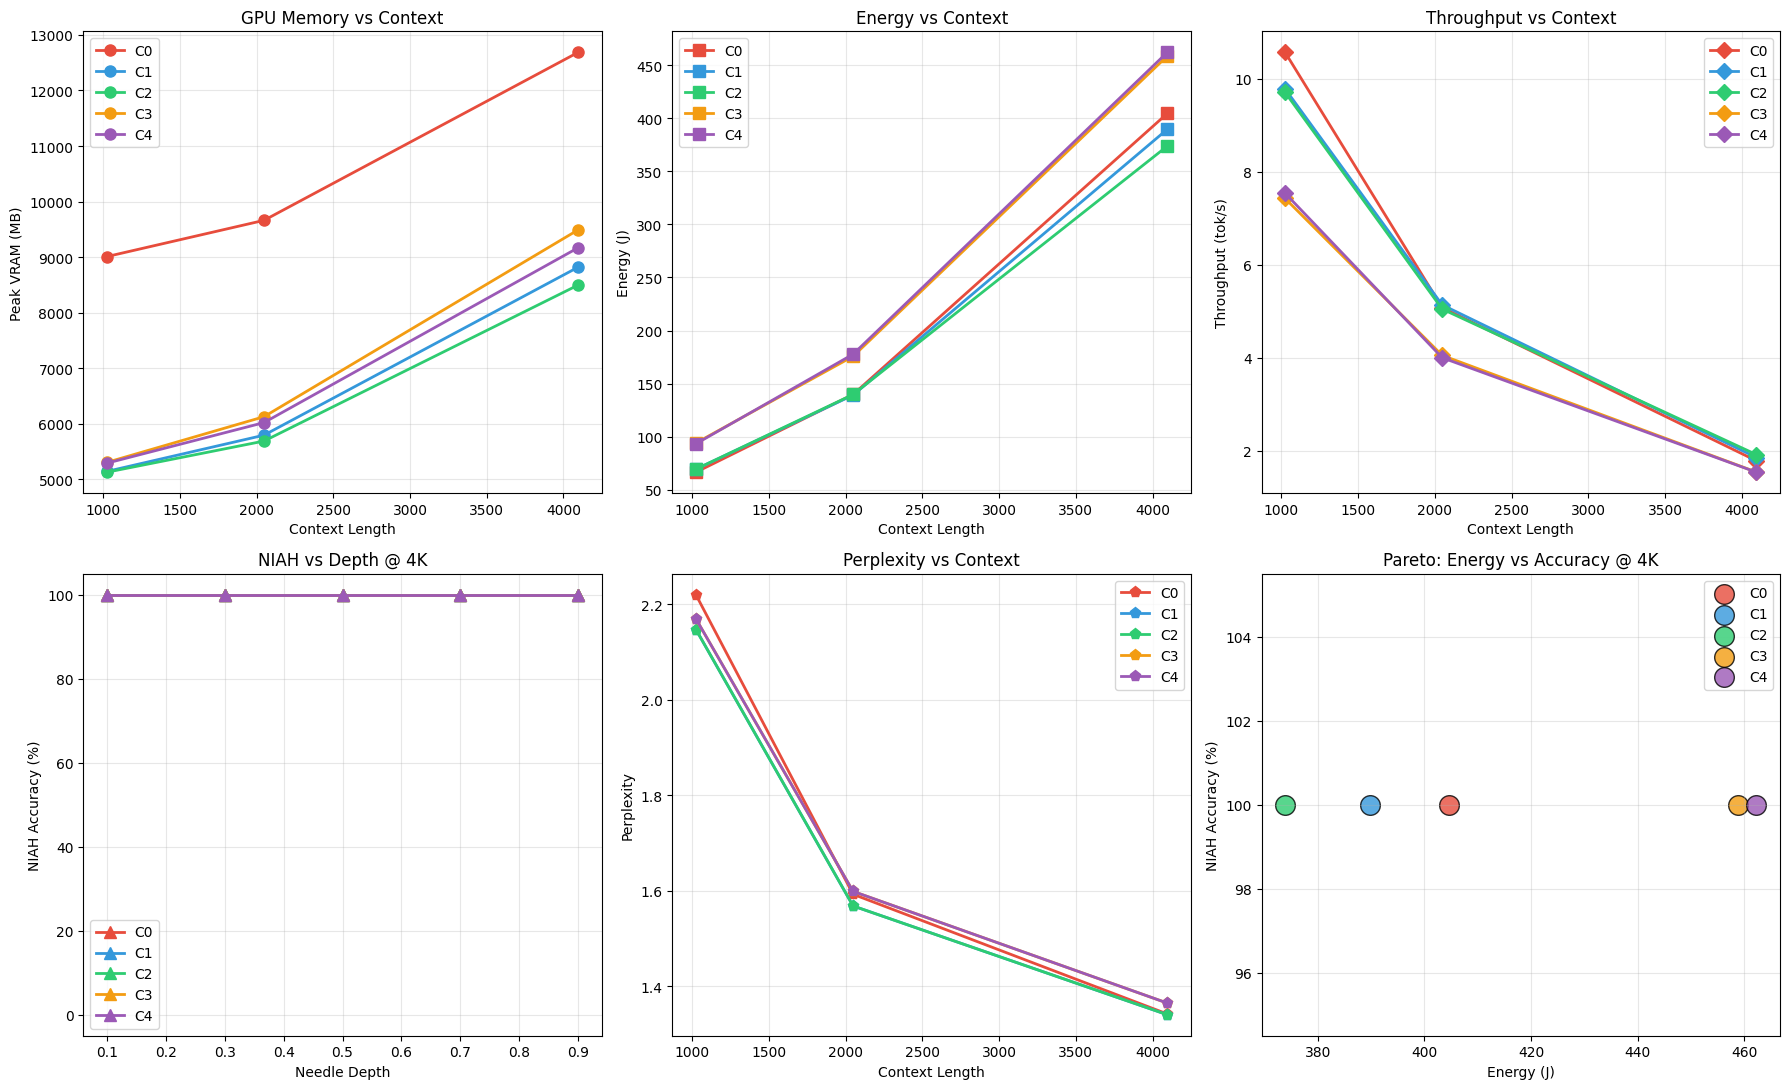


=== Summary Table (averaged over depths) ===


total_s  energy_j  vram_peak_mb  avg_power_w  ppl correct
config context                                                           
C0     1024         1.0      66.4        9009.1         65.2  2.2    100%
       2048         2.2     139.7        9661.4         65.7  1.6    100%
       4096         6.2     404.6       12686.5         66.0  1.3    100%
C1     1024         1.1      69.3        5141.6         63.9  2.1    100%
       2048         2.1     139.1        5793.9         65.9  1.6    100%
       4096         5.9     389.7        8819.0         65.9  1.3    100%
C2     1024         1.1      69.3        5127.0         63.7  2.1    100%
       2048         2.2     139.7        5687.9         64.9  1.6    100%
       4096         5.7     373.9        8497.0         65.5  1.3    100%
C3     1024         1.5      94.0        5304.2         64.2  2.2    100%
       2048         2.7     175.7        6126.3         65.9  1.6    100%
       4096         7.1     458.8        9490.9         64.5  1.4    100%
C4     1024         1.5      93.2        5289.7         64.9  2.2    100%
       2048         2.8     177.7        6020.3         65.9  1.6    100%
       4096         7.2     462.3        9168.9         65.0  1.4    100%

In [12]:
df_valid = df[df['correct'].notna() & ~df.config.str.contains('sanity')].copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
order = ['C0', 'C1', 'C2', 'C3', 'C4']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

# 1. VRAM
ax = axes[0, 0]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        means = d.groupby('context')['vram_peak_mb'].mean()
        ax.plot(means.index, means.values, 'o-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Peak VRAM (MB)', title='GPU Memory vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 2. Energy
ax = axes[0, 1]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        means = d.groupby('context')['energy_j'].mean()
        ax.plot(means.index, means.values, 's-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Energy (J)', title='Energy vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 3. Throughput
ax = axes[0, 2]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        g = d.groupby('context')[['output_tokens', 'total_s']].mean()
        tok_s = g['output_tokens'] / g['total_s']
        ax.plot(tok_s.index, tok_s.values, 'D-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Throughput (tok/s)', title='Throughput vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 4. NIAH by depth (at ctx=4096)
ax = axes[1, 0]
for cfg, c in zip(order, colors):
    d = df_valid[(df_valid['config'] == cfg) & (df_valid['context'] == 4096)]
    if not d.empty:
        means = d.groupby('depth')['correct'].mean() * 100
        ax.plot(means.index, means.values, '^-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Needle Depth', ylabel='NIAH Accuracy (%)', title='NIAH vs Depth @ 4K')
ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(-5, 105)

# 5. PPL
ax = axes[1, 1]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty and 'ppl' in d.columns:
        means = d.groupby('context')['ppl'].mean()
        ax.plot(means.index, means.values, 'p-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Perplexity', title='Perplexity vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 6. Pareto @ 4K
ax = axes[1, 2]
for cfg, c in zip(order, colors):
    sub = df_valid[(df_valid['config'] == cfg) & (df_valid['context'] == 4096)]
    if not sub.empty:
        ax.scatter(sub['energy_j'].mean(), sub['correct'].mean() * 100,
                   s=200, label=cfg, color=c, alpha=0.8, edgecolors='black')
ax.set(xlabel='Energy (J)', ylabel='NIAH Accuracy (%)', title='Pareto: Energy vs Accuracy @ 4K')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ablation_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary table
print('\n=== Summary Table (averaged over depths) ===')
summary = df_valid.groupby(['config', 'context']).agg({
    'total_s': 'mean', 'energy_j': 'mean', 'vram_peak_mb': 'mean',
    'avg_power_w': 'mean', 'ppl': 'mean',
    'correct': lambda x: f"{x.mean()*100:.0f}%",
}).round(1)
display(summary)

## 12. Statistical Tests

In [13]:
from scipy import stats

# Test at ctx=4096, averaged over depths
d = df_valid[df_valid['context'] == 4096]
if not d.empty:
    # Aggregate over depths per (config, run) for paired test
    d_agg = d.groupby(['config', 'run'])['energy_j'].mean().reset_index()

    n_effective = REPETITIONS - WARMUP_DISCARD
    print(f'Paired t-tests: Energy (J) @ 4096 (averaged over depths)')
    print(f'  (n={n_effective} per config, after discarding {WARMUP_DISCARD} warmup)\n')

    pairs = [('C0', 'C1'), ('C1', 'C2'), ('C1', 'C3'), ('C1', 'C4')]
    n_tests = len(pairs)
    alpha_bonf = 0.05 / n_tests

    for c1, c2 in pairs:
        e1 = d_agg[d_agg['config'] == c1]['energy_j'].values
        e2 = d_agg[d_agg['config'] == c2]['energy_j'].values
        if len(e1) == len(e2) and len(e1) > 1:
            t, p = stats.ttest_rel(e1, e2)
            diff = e1 - e2
            std = diff.std(ddof=1)
            d_val = abs(diff.mean() / std) if std > 0 else float('inf')
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < alpha_bonf else 'n.s.'
            delta = e1.mean() - e2.mean()
            pct = (delta / e1.mean()) * 100
            print(f'  {c1} vs {c2}: Δ={delta:+.1f}J ({pct:+.1f}%)  t={t:.2f}  p={p:.4f}  '
                  f"|d|={d_val:.2f}  {sig}")
        else:
            print(f'  {c1} vs {c2}: insufficient data (n1={len(e1)}, n2={len(e2)})')

    print(f'\nBonferroni-adjusted α = 0.05 / {n_tests} = {alpha_bonf:.4f}')
    print("Cohen's d: |d|≥0.2 small, ≥0.5 medium, ≥0.8 large")
else:
    print('No 4096-token data available for statistical tests.')

# Also test NIAH accuracy differences
print('\n=== NIAH Accuracy @ 4096 (proportion test) ===')
for c1, c2 in [('C1', 'C2'), ('C1', 'C3'), ('C1', 'C4')]:
    n1 = d[d.config == c1].shape[0]
    n2 = d[d.config == c2].shape[0]
    k1 = d[d.config == c1].correct.sum()
    k2 = d[d.config == c2].correct.sum()
    if n1 > 0 and n2 > 0:
        acc1 = k1/n1 * 100
        acc2 = k2/n2 * 100
        print(f'  {c1}: {acc1:.0f}% ({int(k1)}/{n1})  vs  '
              f'{c2}: {acc2:.0f}% ({int(k2)}/{n2})')

Paired t-tests: Energy (J) @ 4096 (averaged over depths)
  (n=4 per config, after discarding 1 warmup)

  C0 vs C1: Δ=+14.9J (+3.7%)  t=12.58  p=0.0011  |d|=6.29  **
  C1 vs C2: Δ=+15.8J (+4.1%)  t=12.31  p=0.0012  |d|=6.15  **
  C1 vs C3: Δ=-69.1J (-17.7%)  t=-17.42  p=0.0004  |d|=8.71  ***
  C1 vs C4: Δ=-72.5J (-18.6%)  t=-19.41  p=0.0003  |d|=9.70  ***

Bonferroni-adjusted α = 0.05 / 4 = 0.0125
Cohen's d: |d|≥0.2 small, ≥0.5 medium, ≥0.8 large

=== NIAH Accuracy @ 4096 (proportion test) ===
  C1: 100% (20/20)  vs  C2: 100% (20/20)
  C1: 100% (20/20)  vs  C3: 100% (20/20)
  C1: 100% (20/20)  vs  C4: 100% (20/20)
